# SmartHome AI: Exploratory Data Analysis
Dataset: *Bengaluru House Data* (prices in **lakh ₹**, 1 lakh = ₹100,000). Run from the `notebooks/` folder after downloading the data.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, plotly.express as px
from src.data_preprocessing import load_raw, clean_data, RAW_PATH
sns.set_theme(style='whitegrid'); plt.rcParams['figure.figsize']=(8,4.5)
raw = load_raw(RAW_PATH); df, report = clean_data(raw)
print(raw.shape, '->', df.shape)

(13320, 9) -> (11973, 8)


## 1. Dataset overview and descriptive statistics

In [2]:
display(raw.head()); display(raw.dtypes.to_frame('dtype')); display(raw.describe(include='all').T)

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


,dtype
area_type,str
availability,str
location,str
size,str
society,str
total_sqft,str
bath,float64
balcony,float64
price,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
area_type,13320,4,Super built-up Area,8790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
availability,13320,81,Ready To Move,10581,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,13319,1305,Whitefield,540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size,13304,31,2 BHK,5199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
society,7818,2688,GrrvaGr,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_sqft,13320,2117,1200,843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bath,13247.0,NaN,NaN,NaN,2.69261,1.341458,1.0,2.0,2.0,3.0,40.0
balcony,12711.0,NaN,NaN,NaN,1.584376,0.817263,0.0,1.0,2.0,2.0,3.0
price,13320.0,NaN,NaN,NaN,112.565627,148.971674,8.0,50.0,72.0,120.0,3600.0


## 2. Missing values and duplicates

In [3]:
miss = raw.isna().sum().to_frame('missing'); miss['percent']=(miss.missing/len(raw)*100).round(1); display(miss)
print('Exact duplicate rows:', raw.duplicated().sum())
print({k:v for k,v in report.items() if k!='missing_values'})

,missing,percent
area_type,0,0.0
availability,0,0.0
location,1,0.0
size,16,0.1
society,5502,41.3
total_sqft,0,0.0
bath,73,0.5
balcony,609,4.6
price,0,0.0


Exact duplicate rows: 529
{'raw_rows': 13320, 'duplicate_rows': 529, 'dropped_missing_or_unparseable': 63, 'dropped_invalid_nonpositive': 0, 'dropped_outliers': 755, 'clean_rows': 11973}


`society` is missing for ~41% of rows and is not used as a feature. `balcony` (609) and `bath` (73) are imputed with the training-set median inside the model pipeline. Cleaning rules are in `src/data_preprocessing.py`.

## 3. Price distribution

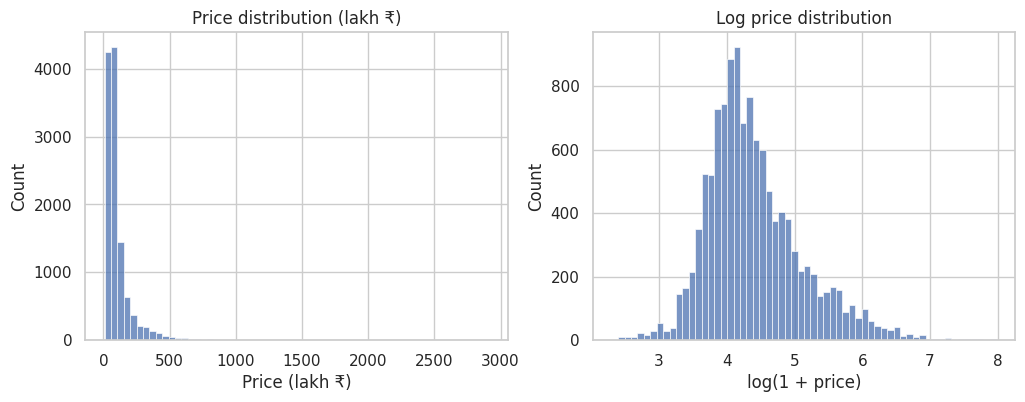

skewness: 7.34


In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(df.price,bins=60,ax=ax[0]); ax[0].set(title='Price distribution (lakh ₹)',xlabel='Price (lakh ₹)')
sns.histplot(np.log1p(df.price),bins=60,ax=ax[1]); ax[1].set(title='Log price distribution',xlabel='log(1 + price)')
plt.show(); print('skewness:', round(df.price.skew(),2))

Prices are strongly right-skewed (skewness ≈ 7.3), so the models predict **log(price)** and convert back to rupees.

## 4. Area vs price

In [5]:
fig=px.scatter(df.sample(3000,random_state=1),x='total_sqft',y='price',color='area_type',opacity=.6,title='Area vs price (sample of 3,000)',labels={'total_sqft':'Area (sq ft)','price':'Price (lakh ₹)'}); fig.show()
print(df[['total_sqft','bhk','bath','balcony','price']].corr().round(2))

            total_sqft   bhk  bath  balcony  price
total_sqft        1.00  0.61  0.64     0.19   0.73
bhk               0.61  1.00  0.87     0.24   0.48
bath              0.64  0.87  1.00     0.24   0.53
balcony           0.19  0.24  0.24     1.00   0.12
price             0.73  0.48  0.53     0.12   1.00


## 5. Bedrooms vs price

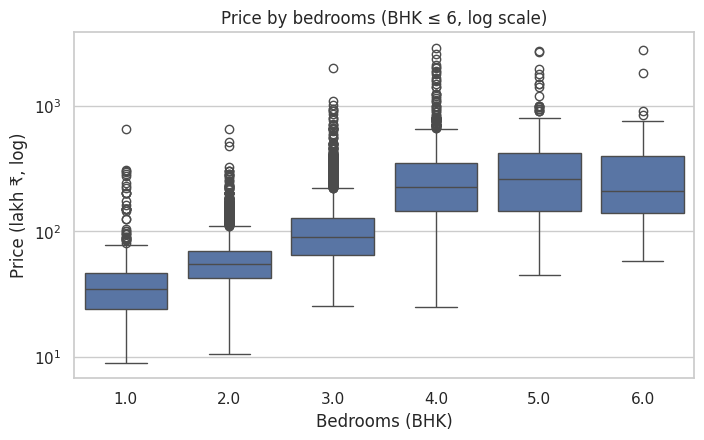

In [6]:
d=df[df.bhk<=6]; plt.figure(); sns.boxplot(data=d,x='bhk',y='price'); plt.yscale('log'); plt.title('Price by bedrooms (BHK ≤ 6, log scale)'); plt.xlabel('Bedrooms (BHK)'); plt.ylabel('Price (lakh ₹, log)'); plt.show()

## 6. Location-wise comparison

In [7]:
g=df.groupby('location').price.agg(['median','count']); g=g[g['count']>=30].sort_values('median')
print(len(g),'locations with >=30 listings'); sel=pd.concat([g.head(8),g.tail(8)]).reset_index()
px.bar(sel,x='median',y='location',orientation='h',title='Median price: 8 cheapest vs 8 most expensive locations (>=30 listings)',labels={'median':'Median price (lakh ₹)'}).show()
print('Locations with <10 listings:', (df.location.value_counts()<10).sum(), 'of', df.location.nunique())

92 locations with >=30 listings


Locations with <10 listings: 974 of 1203


## 7. Property (area) type comparison

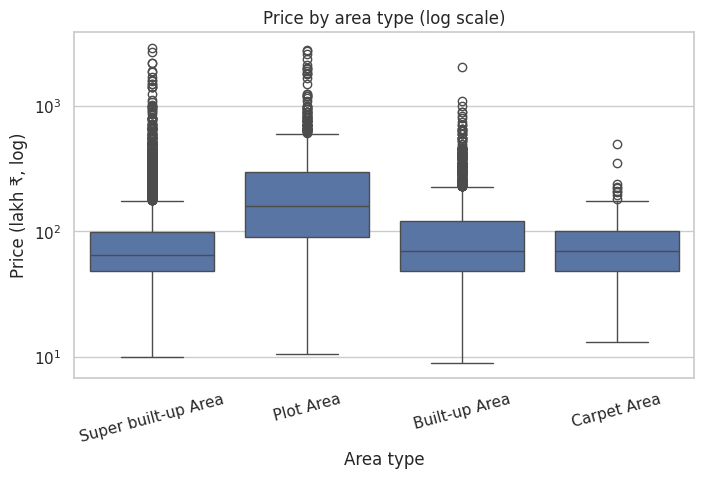

,count,median,mean
area_type,,,
Built-up Area,2309,70.0,104.5
Carpet Area,82,69.5,90.7
Plot Area,1330,160.0,239.9
Super built-up Area,8252,65.2,94.0


In [8]:
plt.figure(); sns.boxplot(data=df,x='area_type',y='price'); plt.yscale('log'); plt.title('Price by area type (log scale)'); plt.xlabel('Area type'); plt.ylabel('Price (lakh ₹, log)'); plt.xticks(rotation=15); plt.show()
display(df.groupby('area_type').price.agg(['count','median','mean']).round(1))

## 8. Correlation

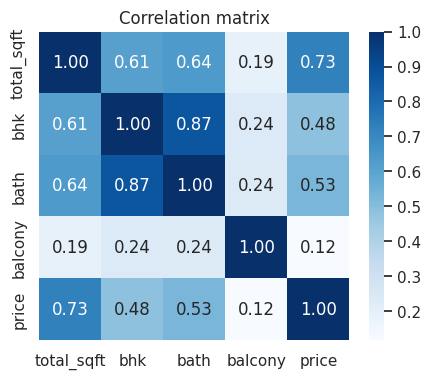

In [9]:
plt.figure(figsize=(5,4)); sns.heatmap(df[['total_sqft','bhk','bath','balcony','price']].corr(),annot=True,fmt='.2f',cmap='Blues'); plt.title('Correlation matrix'); plt.show()

## 9. Outlier investigation

Rows with < 300 sq ft per bedroom: 744
Price/sqft outside 1,000-60,000 INR: 19


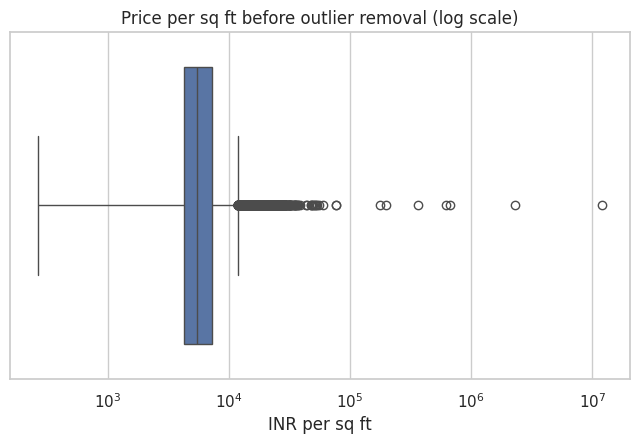

Rows removed as outliers: 755


In [10]:
raw_c=raw.copy(); raw_c['sqft']=pd.to_numeric(raw_c.total_sqft,errors='coerce'); raw_c['bhk']=raw_c['size'].str.extract(r'(\d+)').astype(float)[0]
raw_c['sqft_per_bhk']=raw_c.sqft/raw_c.bhk; raw_c['ppsf']=raw_c.price*1e5/raw_c.sqft
print('Rows with < 300 sq ft per bedroom:', (raw_c.sqft_per_bhk<300).sum())
print('Price/sqft outside 1,000-60,000 INR:', (~raw_c.ppsf.dropna().between(1000,60000)).sum())
plt.figure(); sns.boxplot(x=raw_c.ppsf.dropna()); plt.xscale('log'); plt.title('Price per sq ft before outlier removal (log scale)'); plt.xlabel('INR per sq ft'); plt.show()
print('Rows removed as outliers:', report['dropped_outliers'])

## 10. Key findings (computed from this dataset)
- 13,320 raw rows → 11,973 clean rows (529 exact duplicates, 63 unusable rows, 755 outliers removed).
- Prices are very skewed (median ≈ ₹70 lakh vs mean ≈ ₹112 lakh).
- Area has the strongest linear correlation with price (≈ 0.73); bathrooms ≈ 0.53, bedrooms ≈ 0.48, balconies ≈ 0.12.
- Plot Area listings have a much higher median (≈ ₹160 lakh) than the other three area types (≈ ₹65–70 lakh).
- Median price rises with bedrooms: 1 BHK ≈ ₹34 lakh, 2 BHK ≈ ₹54 lakh, 3 BHK ≈ ₹90 lakh.
- Location matters: among locations with ≥ 30 listings, medians range from ≈ ₹25 lakh (Attibele) to ≈ ₹272 lakh (Malleshwaram).
- Of 1,203 locations, 974 have fewer than 10 listings, so the model groups them as "rare" and is less reliable there.

**Caveat:** these are asking prices in one city, and correlation is not causation.